# Project 4 – Hybrid Recommender · Step 1: Collaborative Filtering
AIM608 end-term project. This notebook covers **"What to build" point 1**:
1. **Item-based CF** – project the user–film bipartite graph onto films; recommend films linked to those the user liked.
2. **Random walk with restart (RWR / personalised PageRank)** – computed by power iteration, plus the warm-up check.
3. **Evaluation** – hide 20% of each user's ratings; precision@10 and recall@10; popularity bias.

**Tools declared:** Claude Code (GenAI) was used to help write the code. Libraries: numpy, scipy, pandas, matplotlib.
**Data:** Harper & Konstan (2015), MovieLens *latest-small* (GroupLens).
**References:** Linden, Smith & York (2003) item-to-item CF; Fouss et al. (2007) random-walk similarities; Brin & Page PageRank.

In [1]:
import numpy as np, pandas as pd, scipy.sparse as sp, matplotlib.pyplot as plt
rng = np.random.default_rng(42)
R = pd.read_csv('data/ml-latest-small/ratings.csv')
M = pd.read_csv('data/ml-latest-small/movies.csv')
print(R.shape, R.userId.nunique(), 'users', R.movieId.nunique(), 'films')
R.head()

(100836, 4) 610 users 9724 films


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## 1. Train/test split (done BEFORE any edge is built, to avoid leakage)
For every user, 20% of their ratings are hidden (at least one). A film counts as **liked** if rated ≥ 4.0.
All graphs below are built from the training ratings only. Test "relevant" items = hidden films the user liked.

In [2]:
LIKE = 4.0
R['u'] = R.userId.astype('category').cat.codes
R['i'] = R.movieId.astype('category').cat.codes
uid = dict(zip(R.u, R.userId)); iid = dict(zip(R.i, R.movieId))
nU, nI = R.u.max()+1, R.i.max()+1

test_idx = []
for u, g in R.groupby('u'):
    k = max(1, int(round(0.2*len(g))))
    test_idx += list(rng.choice(g.index, k, replace=False))
test = R.loc[test_idx]; train = R.drop(test_idx)
print('train', len(train), 'test', len(test))

# Bipartite user-film matrix from TRAIN only, weighted by rating
A = sp.csr_matrix((train.rating, (train.u, train.i)), shape=(nU, nI))
liked_train = sp.csr_matrix(((train.rating>=LIKE).astype(float), (train.u, train.i)), shape=(nU, nI))
seen = sp.csr_matrix((np.ones(len(train)), (train.u, train.i)), shape=(nU, nI))
test_rel = test[test.rating>=LIKE].groupby('u').i.apply(set).to_dict()   # relevant hidden films
n_ratings = np.asarray(seen.sum(0)).ravel()                                # popularity (train)
print('users with >=1 relevant test film:', len(test_rel))

train 80672 test 20164
users with >=1 relevant test film: 602


## 2. Item-based collaborative filtering
Project the bipartite graph onto films: `W = Aᵀ A` links two films when the same users rated them (weighted by co-rating).
Raw co-occurrence favours popular films, so we normalise with **cosine similarity** (columns of `A` L2-normalised).
Score for user *u* = sum of similarities from the films *u* liked. Already-seen films are excluded.

In [3]:
def item_based_scores(u, shrink=0.0):
    liked = liked_train[u]                      # 1 x nI
    return (liked @ S).toarray().ravel()

# cosine item-item similarity on the film projection
norms = np.sqrt(np.asarray(A.multiply(A).sum(0)).ravel()); norms[norms==0] = 1
An = A @ sp.diags(1/norms)
S = (An.T @ An).tocsr(); S.setdiag(0); S.eliminate_zeros()
print('film projection: %d films, %d edges (density %.3f)' % (nI, S.nnz//2, S.nnz/int(nI)**2))

film projection: 9724 films, 9773903 edges (density 0.207)


## 3. Random walk with restart (personalised PageRank)
Build the symmetric bipartite adjacency `G = [[0, A],[Aᵀ, 0]]` over users+films, column-normalise to a transition matrix `P`.
Power iteration: `r ← (1-c)·P·r + c·e_u`, with restart probability `c` (here 0.15), where `e_u` is the indicator of the start user.
Films are ranked by their stationary visit probability. We use **all rating edges weighted by rating** in this step.

In [4]:
N = nU + nI
G = sp.bmat([[None, A],[A.T, None]], format='csr')
deg = np.asarray(G.sum(0)).ravel(); deg[deg==0] = 1
P = G @ sp.diags(1/deg)                         # column-stochastic

def rwr(u, c=0.15, tol=1e-10, maxit=200, return_iters=False):
    e = np.zeros(N); e[u] = 1
    r = e.copy()
    for it in range(maxit):
        r_new = (1-c)*(P @ r) + c*e
        if np.abs(r_new-r).sum() < tol: r = r_new; break
        r = r_new
    return (r, it+1) if return_iters else r

### Warm-up check
Compute personalised PageRank for one user. Sanity checks:
(a) it converges and sums to 1; (b) top films are ones rated highly by users similar to this user; (c) compare with the plain item-based ranking.

In [5]:
u0 = 0
r, iters = rwr(u0, return_iters=True)
print('converged in', iters, 'iterations; sum =', r.sum().round(6))
film_r = r[nU:]
def titles(idx): return [M.set_index('movieId').title.get(iid[i], '?') for i in idx]

top_rwr = [i for i in np.argsort(-film_r) if seen[u0, i]==0][:10]
fav = train[train.u==u0].sort_values('rating', ascending=False).head(8)
print('User', uid[u0], 'top-rated films:', titles(fav.i))
print('\nRWR recommendations (unseen):'); [print('  ', t) for t in titles(top_rwr)]

# Do the top films come from similar users?  Find neighbours = users with highest visit prob.
nb = np.argsort(-r[:nU])[1:6]
print('\nMost-visited neighbour users:', [uid[x] for x in nb])
agree = np.mean([A[nb][:, i].sum()>0 for i in top_rwr])
print('Fraction of RWR top-10 films that these 5 neighbours rated:', agree)

converged in 146 iterations; sum = 1.0
User 1 top-rated films: ['Usual Suspects, The (1995)', 'Seven (a.k.a. Se7en) (1995)', 'Canadian Bacon (1995)', 'Bottle Rocket (1996)', 'Rob Roy (1995)', "Schindler's List (1993)", 'Jungle Book, The (1994)', 'Dumb & Dumber (Dumb and Dumber) (1994)']

RWR recommendations (unseen):


   Forrest Gump (1994)
   Shawshank Redemption, The (1994)
   Pulp Fiction (1994)
   Star Wars: Episode IV - A New Hope (1977)
   Jurassic Park (1993)
   Terminator 2: Judgment Day (1991)
   Godfather, The (1972)
   Fight Club (1999)
   Apollo 13 (1995)
   Lord of the Rings: The Fellowship of the Ring, The (2001)

Most-visited neighbour users: [414, 474, 599, 448, 274]
Fraction of RWR top-10 films that these 5 neighbours rated: 1.0


## 4. Evaluation: precision@10 and recall@10

In [6]:
def topk(scores, u, k=10):
    scores = scores.copy(); scores[seen[u].indices] = -np.inf    # exclude training items
    idx = np.argpartition(-scores, k)[:k]
    return idx[np.argsort(-scores[idx])]

def evaluate(score_fn, users, k=10):
    P_, R_, rec = [], [], []
    for u in users:
        rel = test_rel[u]; top = topk(score_fn(u), u, k); rec.append(top)
        hit = len(rel & set(top)); P_.append(hit/k); R_.append(hit/len(rel))
    return np.mean(P_), np.mean(R_), np.concatenate(rec)

pop_score = lambda u: n_ratings.astype(float)
item_score = lambda u: item_based_scores(u)
rwr_score = lambda u: rwr(u)[nU:]

users = sorted(test_rel)
users_eval = list(rng.choice(users, 200, replace=False))   # RWR per-user is costly; 200 random users
res, recs = {}, {}
for name, fn in [('Popularity baseline', pop_score), ('Item-based CF', item_score), ('Random walk w/ restart', rwr_score)]:
    p, r_, rec = evaluate(fn, users_eval); res[name] = (p, r_); recs[name] = rec
out = pd.DataFrame(res, index=['precision@10','recall@10']).T.round(4); out

,precision@10,recall@10
Popularity baseline,0.1140,0.0954
Item-based CF,0.1570,0.1772
Random walk w/ restart,0.1455,0.1413


## 5. Popularity check
Share of recommended films that fall **outside the top 10% most-rated films** (the long tail), i.e. how much the method escapes popularity bias.

In [7]:
top10 = set(np.argsort(-n_ratings)[:int(0.1*nI)])
tail = {n: np.mean([i not in top10 for i in rec]) for n, rec in recs.items()}
pd.DataFrame({'precision@10':out['precision@10'],'recall@10':out['recall@10'],
              'share outside top-10% popular':pd.Series(tail).round(3)})

,precision@10,recall@10,share outside top-10% popular
Popularity baseline,0.1140,0.0954,0.000
Item-based CF,0.1570,0.1772,0.028
Random walk w/ restart,0.1455,0.1413,0.000


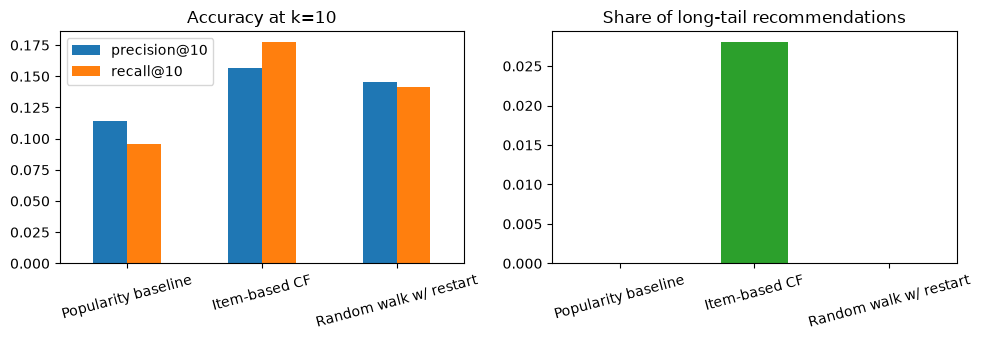

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
out.plot.bar(ax=ax[0], rot=15); ax[0].set_title('Accuracy at k=10')
pd.Series(tail).plot.bar(ax=ax[1], rot=15, color='tab:green'); ax[1].set_title('Share of long-tail recommendations')
plt.tight_layout(); plt.savefig('fig_step1.png', dpi=130); plt.show()

In [9]:
# Sensitivity of RWR to restart probability c
rows = []
for c in [0.05, 0.15, 0.3, 0.5]:
    p, r_, _ = evaluate(lambda u: rwr(u, c=c)[nU:], users_eval[:100])
    rows.append((c, round(p,4), round(r_,4)))
pd.DataFrame(rows, columns=['restart c','precision@10','recall@10'])

,restart c,precision@10,recall@10
0,0.05,0.144,0.1060
1,0.15,0.160,0.1254
2,0.30,0.168,0.1326
3,0.50,0.172,0.1364


## Summary of Step 1
* Built two collaborative-filtering recommenders from the training graph only: **item-based CF** (film–film projection, cosine-normalised) and **RWR / personalised PageRank** (power iteration).
* Warm-up verified: RWR converges, probabilities sum to 1, and its top films are rated by the user's walk-neighbours.
* Evaluated with a 20% per-user hold-out; precision/recall@10 and popularity share reported above, with a popularity baseline for context.

Next steps (points 2–4): content embeddings with sentence-transformers, hybrid graph with weighted content edges, cold-start test.